In [ ]:
import os
import re
import OpenEXR
import Imath
import numpy as np
import torch
import torch.nn as nn
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms

In [ ]:
WP_MAX = 1e6  #10 km in cm; beyond this is sky, not geometry
SIZE_ALIGN = 16  # UNet downsamples by 8; raise to 16 for a stride-2 stem

def load_exr(path):
    file = OpenEXR.InputFile(path)
    dw = file.header()["dataWindow"]

    h = dw.max.y - dw.min.y + 1
    w = dw.max.x - dw.min.x + 1

    pt = Imath.PixelType(Imath.PixelType.FLOAT)
    channels = ["R", "G", "B"]

    data = [
        np.frombuffer(file.channel(c, pt), dtype=np.float32).reshape(h, w)
        for c in channels
    ]
    return np.stack(data, axis=-1).copy()  # HWC, writable

def wp_valid(wp):
    """True where world position is real geometry, not a background ray."""
    return (
        np.isfinite(wp).all(-1)
        & (np.abs(wp) < WP_MAX).all(-1)
        & (np.abs(wp).sum(-1) > 0)
    )

def load_frame(clip, frame, keys=None, align=SIZE_ALIGN):
    '''One frame's buffers, cropped to a common size divisible by `align`.'''
    clip = Path(clip)
    keys = keys or list(BUFFERS)

    bufs = {}
    for k in keys:
        top, sub = BUFFERS[k]
        d = clip / top / sub if sub else clip / top
        bufs[k] = load_exr(str(d / f"{frame}.exr"))

    h = (min(v.shape[0] for v in bufs.values()) // align) * align
    w = (min(v.shape[1] for v in bufs.values()) // align) * align
    return {k: v[:h, :w] for k, v in bufs.items()}

BUFFERS = {
    "color": ("A_1spp", None),
    "reference": ("B_2048spp", None),
    "albedo": ("C_gbuffer", "Albedo"),
    "shading_normal": ("C_gbuffer", "Normal"),
    "world_position": ("C_gbuffer", "WorldPosition"),
    "depth": ("C_gbuffer", "Depth"),
    "motion": ("C_gbuffer", "MotionVectors"),
}

def find_clips(root):
    '''[(scene, sequence, clip_path)] - located by A_1spp, whatever the depth.'''
    root = Path(root)
    if not root.is_dir():
        raise FileNotFoundError(f"root not found: {root}")

    out = []
    for a in sorted(root.rglob("A_1spp")):
        if not a.is_dir():
            continue
        clip = a.parent
        rel = clip.relative_to(root).parts      # (scene, sequence, clipNN)
        scene = rel[0]
        seq = rel[1] if len(rel) > 2 else ""
        out.append((scene, seq, clip))

    if not out:
        raise RuntimeError(f"no A_1spp directories under {root}")
    return out

def decode_motion(mv, H, W):
    '''manifest: dx_px = (R-0.5)*2*W, dy_px = -(G-0.5)*2*H;
    pixel (x,y) at t came from (x-dx, y-dy) at t-1.'''
    valid = (mv[..., 0] <= 1.0) & (mv[..., 1] <= 1.0)
    dx = (mv[..., 0] - 0.5) * 2 * W
    dy = -(mv[..., 1] - 0.5) * 2 * H
    return -dx, -dy, valid

def fit_world_position(clip_list, align=SIZE_ALIGN):
    '''One normalisation per scene, so clips of the same scene agree.

    Fitted per clip, the same geometry got scales differing by 1000x between
    clips, and sky pixels at ~1e18 set the scale outright, crushing real
    geometry to numerical zero.
    '''
    stats = {}
    for scene in sorted({s for s, _, _ in clip_list}):
        pts = []
        for s, _, c in clip_list:
            if s != scene:
                continue
            frames = sorted(p.stem for p in (c / "A_1spp").glob("*.exr"))
            for f in frames[:: max(1, len(frames) // 3)]:
                wp = load_frame(c, f, ["world_position"], align)["world_position"]
                pts.append(wp[wp_valid(wp)])

        pts = np.concatenate(pts)
        lo, hi = np.percentile(pts, [1, 99], axis=0)
        center = ((lo + hi) / 2).astype(np.float32)
        scale = max(float(np.max(hi - lo) / 2), 1.0)
        stats[scene] = (center, scale)
        print(f"{scene:30s} center {center.round(1)}  scale {scale:9.2f}")

    return stats

def warp(img, map_x, map_y, interp=cv2.INTER_LINEAR):
    return cv2.remap(
        img, map_x, map_y, interp, borderMode=cv2.BORDER_CONSTANT, borderValue=0
    )

In [ ]:
POS_LIMIT_SQ = 4e-4  # normalised world units; 0.02 ~= 10cm at a 500cm scene scale
NORM_LIMIT_SQ = 1.0  # unit normals; ~60 degrees, BMFR's shipped value

class UEClipDataset(Dataset):
    '''One Unreal capture clip.

    Frame numbering restarts per clip, so one instance per clip is what keeps
    temporal pairs from crossing clip boundaries.
    '''

    EPS = 1e-2

    def __init__(
        self,
        clip_dir,
        transform=None,
        patch=None,
        patches_per_frame=1,
        train=True,
        keys=None,
        wp_stats=None,
        align=SIZE_ALIGN,
    ):
        self.clip = Path(clip_dir)
        if not (self.clip / "A_1spp").is_dir():
            raise ValueError(
                f"{self.clip} is not a clip directory - pass a clip path from "
                f"find_clips(), not the dataset root"
            )

        self.transform = transform
        self.patch = patch
        self.ppf = patches_per_frame
        self.train = train
        self.align = align
        self.keys = keys or [
            "color",
            "reference",
            "albedo",
            "shading_normal",
            "world_position",
        ]

        self.dirs = {}
        for k in self.keys:
            top, sub = BUFFERS[k]
            d = self.clip / top / sub if sub else self.clip / top
            if not d.is_dir():
                raise FileNotFoundError(f"missing buffer dir: {d}")
            self.dirs[k] = d

        stems = {p.stem for p in self.dirs["color"].glob("*.exr")}
        for d in self.dirs.values():
            stems &= {p.stem for p in d.glob("*.exr")}
        self.frames = sorted(stems)
        if not self.frames:
            raise RuntimeError(f"no frames common to all buffers in {self.clip}")

        # consecutive pairs within this clip, for the temporal stage
        self.pairs = [
            (a, b) for a, b in zip(self.frames, self.frames[1:]) if int(b) == int(a) + 1
        ]

        if wp_stats is None:
            raise ValueError(
                "wp_stats is required - call fit_world_position(clips) once and "
                "pass this clip's scene entry, so clips of a scene share a scale"
            )
        self.wp_center, self.wp_scale = wp_stats

    def __len__(self):
        return len(self.pairs) * self.ppf
    
    def _prepare(self, bufs):
        "Raw buffers -> network space. Both frames go through this identically"
        bufs = {k:np.ascontiguousarray(v, dtype=np.float32)
                for k,v  in bufs.items()}
        
        for k in ("color", "reference"):
            if k in bufs:
                bufs[k] = np.clip(bufs[k], 0, None)
                
        albedo = np.clip(bufs["albedo"], 0, None)
        denom = albedo + self.EPS
        for k in ("color", "reference"):
            if k in bufs:
                bufs[k] = np.log1p(bufs[k] / denom)
        bufs["albedo"] = albedo
        
        bufs["shading_normal"] = bufs["shading_normal"] * 2.0 - 1.0

        wp = bufs["world_position"]
        ok = wp_valid(wp)[..., None]
        wp = (wp - self.wp_center) / self.wp_scale
        bufs["world_position"] = np.clip(np.where(ok, wp, 0.0), -4.0, 4.0).astype(np.float32)

        return bufs 

    def __getitem__(self, idx):
        prev_name, curr_name = self.pairs[idx // self.ppf]

        curr = self._prepare(load_frame(
            self.clip, curr_name,
            ["color", "reference", "albedo", "shading_normal", "world_position"],
            self.align))
        prev = self._prepare(load_frame(
            self.clip, prev_name,
            ["reference", "albedo", "shading_normal", "world_position"],
            self.align))

        mv = load_frame(self.clip, curr_name, ["motion"], self.align)["motion"]
        h, w = mv.shape[:2]

        # ---- reproject frame n-1 into frame n, at full resolution ----
        mv_x, mv_y, mv_ok = decode_motion(mv, h, w)
        yy, xx = np.mgrid[0:h, 0:w]
        map_x = (xx + mv_x).astype(np.float32)
        map_y = (yy + mv_y).astype(np.float32)

        # History is the previous frame's clean output, in the space the model
        # predicts in, so a warp here matches what inference will do.
        hist = warp(prev["reference"], map_x, map_y, cv2.INTER_LINEAR)

        # Nearest on the validation buffers: bilinear across a depth discontinuity
        # blends two surfaces into a value belonging to neither.
        w_wp = warp(prev["world_position"], map_x, map_y, cv2.INTER_NEAREST)
        w_sn = warp(prev["shading_normal"], map_x, map_y, cv2.INTER_NEAREST)

        in_bounds = (map_x >= 0) & (map_x < w) & (map_y >= 0) & (map_y < h)
        pos_ok = ((w_wp - curr["world_position"]) ** 2).sum(-1) < POS_LIMIT_SQ
        norm_ok = ((w_sn - curr["shading_normal"]) ** 2).sum(-1) < NORM_LIMIT_SQ

        valid = (mv_ok & in_bounds & pos_ok & norm_ok).astype(np.float32)
        hist = hist * valid[..., None]

        curr["history"] = np.ascontiguousarray(hist, dtype=np.float32)
        curr["valid"] = np.ascontiguousarray(valid[..., None], dtype=np.float32)
        curr["map_xy"] = np.stack([map_x, map_y], axis=-1)

        # crop last, with one origin shared by every buffer 
        if self.patch:
            p = self.patch
            if self.train:
                y = torch.randint(0, h - p + 1, (1,)).item()
                x = torch.randint(0, w - p + 1, (1,)).item()
            else:
                y, x = (h - p) // 2, (w - p) // 2
            curr = {k: v[y:y + p, x:x + p] for k, v in curr.items()}

        return {k: torch.from_numpy(np.ascontiguousarray(v)).permute(2, 0, 1).contiguous()
                for k, v in curr.items()}

In [4]:
# transform_dataset = transforms.Compose([
#     transforms.Lambda(lambda x: torch.from_numpy(x).permute(2, 0, 1).contiguous()),
#     transforms.Lambda(torch.log1p),
# ])

In [ ]:
# Build cache - current dataset requires 25.6GB

CACHE_CHANNELS = [
    ("color", 3),
    ("reference", 3),
    ("albedo", 3),
    ("shading_normal", 3),
    ("world_position", 3),
    ("history", 3),
    ("valid", 1),
]
CACHE_TOTAL = sum(n for _, n in CACHE_CHANNELS)  # 19

def build_pair_cache(clip, wp_stats, out_path, align=SIZE_ALIGN, force=False):
    '''Precompute warp + validation per pair into a float16 memmap.

    Rebuild whenever POS_LIMIT_SQ, NORM_LIMIT_SQ, wp_stats or decode_motion change -
    the cache bakes all of them in.
    '''
    out_path = Path(out_path)
    if out_path.exists() and not force:
        return out_path

    src = UEClipDataset(
        clip, patch=None, patches_per_frame=1, train=False, wp_stats=wp_stats
    )
    arr = None

    for i in range(len(src)):
        s = src[i]  # CHW tensors, full frame
        stacked = torch.cat([s[k] for k, _ in CACHE_CHANNELS], dim=0).numpy()

        if arr is None:
            _, h, w = stacked.shape
            out_path.parent.mkdir(parents=True, exist_ok=True)
            arr = np.lib.format.open_memmap(
                out_path,
                mode="w+",
                dtype=np.float16,
                shape=(len(src), CACHE_TOTAL, h, w),
            )
        arr[i] = stacked.astype(np.float16)

    arr.flush()
    del arr
    print(f"{out_path.name}: {len(src)} pairs, {out_path.stat().st_size / 1e9:.2f} GB")
    return out_path

In [6]:
class CachedPairDataset(Dataset):
    """Reads precomputed pairs. __getitem__ is a slice, not a decode."""

    def __init__(self, cache_path, patch=None, patches_per_frame=1, train=True):
        self.path = Path(cache_path)
        self.patch = patch
        self.ppf = patches_per_frame
        self.train = train
        self.arr = None  # opened lazily, per worker

        head = np.load(self.path, mmap_mode="r")
        self.n, _, self.h, self.w = head.shape
        del head

        self.slices, o = {}, 0
        for name, c in CACHE_CHANNELS:
            self.slices[name] = slice(o, o + c)
            o += c

    def __len__(self):
        return self.n * self.ppf

    def __getitem__(self, idx):
        if self.arr is None:  # memmaps don't survive fork
            self.arr = np.load(self.path, mmap_mode="r")

        i = idx // self.ppf
        if self.patch:
            p = self.patch
            if self.train:
                y = torch.randint(0, self.h - p + 1, (1,)).item()
                x = torch.randint(0, self.w - p + 1, (1,)).item()
            else:
                y, x = (self.h - p) // 2, (self.w - p) // 2
            block = np.asarray(self.arr[i, :, y : y + p, x : x + p], dtype=np.float32)
        else:
            block = np.asarray(self.arr[i], dtype=np.float32)

        return {
            k: torch.from_numpy(np.ascontiguousarray(block[s]))
            for k, s in self.slices.items()
        }

In [ ]:
# Dataset construction
from pathlib import Path
from collections import Counter

CACHE = Path("./cache")

ROOT = "./DenoiseData"
clips = find_clips(ROOT)
wp_stats = fit_world_position(clips)

cache_paths = {}
for s, _, c in clips:
    key = f"{s}_{c.name}".replace(" ", "_")
    cache_paths[(s, c)] = build_pair_cache(c, wp_stats[s], CACHE / f"{key}.npy")
    
counts = Counter(s for s, _, _ in clips)
for scene, n in sorted(counts.items()):
    print(f"{scene:28s} {n} clips")
print(f"\n{len(clips)} clips across {len(counts)} scenes")

HELD_OUT = {"ClassicSponzaUnreal"}

train_clips = [c for c in clips if c[0] not in HELD_OUT]
val_clips = [c for c in clips if c[0] in HELD_OUT]

train_ds = ConcatDataset(
    [
        CachedPairDataset(
            build_pair_cache(c, wp_stats[s], CACHE / f"{s}_{c.name}.npy"),
            patch=256,
            patches_per_frame=16,
            train=True,
        )
        for s, _, c in train_clips
    ]
)

val_ds = ConcatDataset(
    [
        CachedPairDataset(
            build_pair_cache(c, wp_stats[s], CACHE / f"{s}_{c.name}.npy"),
            patch=256,
            patches_per_frame=1,
            train=False,
        )
        for s, _, c in val_clips
    ]
)

print(f"train {len(train_ds)} patches / {len(train_clips)} clips")
print(f"val   {len(val_ds)} patches / {len(val_clips)} clips")

BookStackBPV2                  center [2.31700e+02 1.35000e+01 2.81559e+05]  scale 281539.02
Car Dealer                     center [   753.8   1580.9 248524.2]  scale 248415.33
ClassicSponzaUnreal            center [267.6 605.7 511.9]  scale    605.72
Factory_Pack_V1                center [1222.4 3326.1  653.5]  scale   3326.08
IndustrialStageSet             center [339.3 332.7 257.2]  scale    339.28
Modern House Pack V1           center [   630.    1719.8 224996. ]  scale 224895.95
Optimal Gas Station            center [7398.  5787.4  600.4]  scale   7397.97
Post Soviet Hospital Corridor  center [390.  335.6 180. ]  scale    390.00
RustyCarsFree                  center [30045.9 12601.8  3056.9]  scale  30045.94
Sicka_Ancient_Kit              center [3.350196e+05 4.297000e+02 4.379569e+05]  scale 437936.86
Sicka_Scifi_Interior           center [258.8 569.1 203.8]  scale    569.08
Sicka_Scifi_Interior2          center [1319.2 1012.4  336.9]  scale   1319.17
cigar room                  

In [ ]:
# Per-buffer resolution: A/B and C - currently (540, 960, 3)
inspect_clip = clips[0][2]
for k, (top, sub) in BUFFERS.items():
    d = inspect_clip / top / sub if sub else inspect_clip / top
    f = sorted(d.glob("*.exr"))[0]
    print(f"{k:16s} {load_exr(str(f)).shape}")

color            (540, 960, 3)
reference        (540, 960, 3)
albedo           (540, 960, 3)
shading_normal   (540, 960, 3)
world_position   (540, 960, 3)
depth            (540, 960, 3)
motion           (540, 960, 3)


In [9]:
# Raw radiance: want unbounded HDR, a small negative fraction, nothing non-finite.
c = load_exr(str(inspect_clip / "A_1spp" / "0000.exr"))
r = load_exr(str(inspect_clip / "B_2048spp" / "0000.exr"))
for n, x in [("color", c), ("reference", r)]:
    print(f"{n:10s} min {x.min():10.4f}  max {x.max():10.4f}  "
          f"neg {100 * (x < 0).mean():5.2f}%  nonfinite {(~np.isfinite(x)).sum()}")

color      min     0.0000  max     2.4434  neg  0.00%  nonfinite 0
reference  min     0.0000  max     3.2246  neg  0.00%  nonfinite 0


In [ ]:
# After the dataset's processing.
#   color/reference  ~0 to 5   (log1p of demodulated radiance)
#   shading_normal   -1 to 1
#   world_position   ~-1 to 1

inspect_scene, _, inspect_clip = clips[0]
inspect_ds = UEClipDataset(inspect_clip, transform=None, keys=list(BUFFERS), wp_stats=wp_stats[inspect_scene])
sample = inspect_ds[0]
for k, v in sample.items():
    print(f"{k:16s} {tuple(v.shape)}  min {v.min():9.3f}  "
          f"max {v.max():9.3f}  mean {v.mean():8.3f}")

n = sample["shading_normal"].numpy()
print(f"\nnormal unit length (want ~1.0): {np.linalg.norm(n, axis=0).mean():.3f}")

color            (3, 528, 960)  min     0.000  max     3.450  mean    0.088
reference        (3, 528, 960)  min     0.000  max     3.620  mean    0.111
albedo           (3, 528, 960)  min     0.000  max     1.000  mean    0.538
shading_normal   (3, 528, 960)  min    -1.000  max     1.000  mean   -0.353
world_position   (3, 528, 960)  min    -1.000  max     0.001  mean   -0.333
history          (3, 528, 960)  min     0.000  max     2.132  mean    0.107
valid            (1, 528, 960)  min     0.000  max     1.000  mean    0.961
map_xy           (2, 528, 960)  min    -3.200  max   975.637  mean  377.934

normal unit length (want ~1.0): 1.682


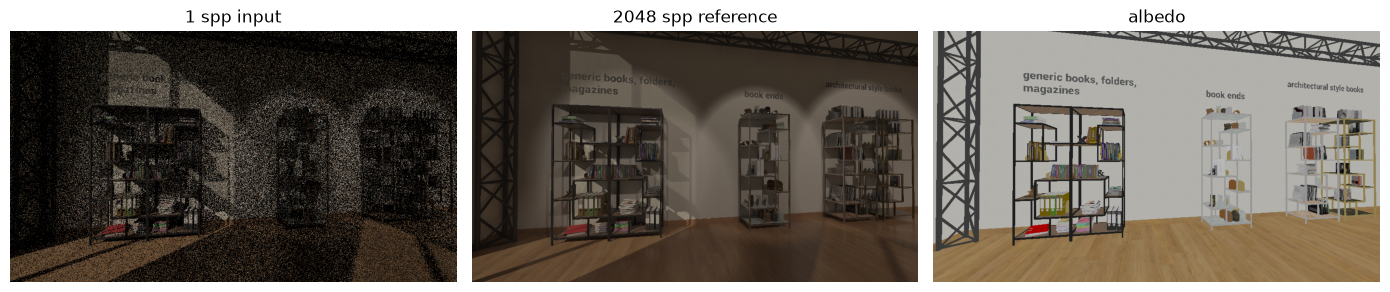

In [ ]:
def show(x, title):
    x = np.clip(x, 0, None)
    plt.imshow((x / (1 + x)) ** (1 / 2.2))
    plt.title(title)
    plt.axis("off")

plt.figure(figsize=(14, 4))
plt.subplot(131); show(load_exr(str(inspect_clip / "A_1spp" / "0000.exr")), "1 spp input")
plt.subplot(132); show(load_exr(str(inspect_clip / "B_2048spp" / "0000.exr")), "2048 spp reference")
plt.subplot(133); show(load_exr(str(inspect_clip / "C_gbuffer" / "Albedo" / "0000.exr")), "albedo")
plt.tight_layout()

In [12]:
# Split and loaders
# Held out by **scene**, not clip - clips from one scene share geometry.

print(f"train {len(train_ds)} patches / {len(train_clips)} clips "
      f"/ {len({s for s, _, _ in train_clips})} scenes")

print(f"val   {len(val_ds)} patches / {len(val_clips)} clips "
      f"/ {len({s for s, _, _ in val_clips})} scenes")

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=4,
                          pin_memory=True, persistent_workers=True, drop_last=True)

val_loader = DataLoader(val_ds, batch_size=8, shuffle=False,
                        num_workers=2, pin_memory=True)

train 13984 patches / 46 clips / 12 scenes
val   95 patches / 5 clips / 1 scenes


In [ ]:
#  Helpers

EPS = UEClipDataset.EPS

def make_input(batch):
    '''16 channels: demodulated log color, normal, albedo, normalised world position, history'''
    return torch.cat(
        [
            batch["color"],
            batch["shading_normal"],
            batch["albedo"],
            batch["world_position"],
            batch["history"],
            batch["valid"],
        ],
        dim=1,
    )

def gradient_loss(pred, target):
    dx = (pred[..., :, 1:] - pred[..., :, :-1]) - (target[..., :, 1:] - target[..., :, :-1])
    dy = (pred[..., 1:, :] - pred[..., :-1, :]) - (target[..., 1:, :] - target[..., :-1, :])
    return dx.abs().mean() + dy.abs().mean()

def tonemap(x):
    x = x / (1.0 + x)
    return x.clamp(0, 1) ** (1 / 2.2)

@torch.no_grad()
def psnr(pred_log, target_log, albedo, eps=1e-8):
    '''Remodulated, tonemapped, reduced per image. 
    Returns the SUM over the batch.'''
    denom = albedo.clamp(min=0) + EPS
    pred = tonemap(torch.expm1(pred_log.float()).clamp(min=0) * denom)
    target = tonemap(torch.expm1(target_log.float()).clamp(min=0) * denom)
    mse = ((pred - target) ** 2).mean(dim=(1, 2, 3))
    return (10 * torch.log10(1.0 / (mse + eps))).sum().item()

In [ ]:
@torch.no_grad()
def evaluate_scenes(model, clip_list, device, tag=""):
    '''Full-frame PSNR, aggregated per scene'''
    model.eval()
    totals = {}

    for scene, _, clip in clip_list:
        ds = UEClipDataset(clip, transform=None,
                           patch=None, patches_per_frame=1, train=False, wp_stats=wp_stats[scene])
        loader = DataLoader(ds, batch_size=1, shuffle=False, num_workers=2)

        for batch in loader:
            x = make_input(batch).to(device, non_blocking=True)
            y = batch["reference"].to(device, non_blocking=True)
            a = batch["albedo"].to(device, non_blocking=True)

            with torch.autocast("cuda", dtype=torch.bfloat16,
                                enabled=(device.type == "cuda")):
                pred = model(x)

            s, n = totals.get(scene, (0.0, 0))
            totals[scene] = (s + psnr(pred, y, a), n + x.shape[0])

    results = {k: s / n for k, (s, n) in totals.items()}
    width = max(len(k) for k in results)
    for k, v in results.items():
        print(f"  {k:<{width}s}  {v:6.2f} dB")
    mean = sum(results.values()) / len(results)
    print(f"  {'mean':<{width}s}  {mean:6.2f} dB {tag}")
    return mean

@torch.no_grad()
def input_psnr(clip_list, device):
    '''PSNR of the noisy input itself. Every model number needs this floor to mean anything.'''
    totals = {}
    for scene, _, clip in clip_list:
        ds = UEClipDataset(clip, transform=None,
                           patch=None, patches_per_frame=1, train=False, wp_stats=wp_stats[scene])
       
        loader = DataLoader(ds, batch_size=1, shuffle=False, num_workers=2)
        for b in loader:
            c = b["color"].to(device)          # already demodulated + log1p
            y = b["reference"].to(device)
            a = b["albedo"].to(device)
            s, n = totals.get(scene, (0.0, 0))
            totals[scene] = (s + psnr(c, y, a), n + c.shape[0])

    results = {k: s / n for k, (s, n) in totals.items()}
    width = max(len(k) for k in results)
    for k, v in results.items():
        print(f"  {k:<{width}s}  input {v:6.2f} dB")
    return results

In [15]:
# shapes 

batch = next(iter(train_loader))
x = make_input(batch)
print(x.shape, batch["reference"].shape, x.dtype)
print("finite:", torch.isfinite(x).all().item(),
      torch.isfinite(batch["reference"]).all().item())

torch.Size([32, 16, 256, 256]) torch.Size([32, 3, 256, 256]) torch.float32
finite: True True


In [ ]:
from unet import UnetStem

m = UnetStem(16, 3, features=(48, 96, 192, 384), stem=True)
x = torch.randn(1, 16, 512, 960)
y = m(x)
print(y.shape)  # want [1, 3, 512, 960]
print(f"{sum(p.numel() for p in m.parameters()) / 1e6:.2f}M params")

torch.Size([1, 3, 512, 960])
18.07M params


In [ ]:
for s, _, c in clips:
    ds = UEClipDataset(c, patch=256, patches_per_frame=16, wp_stats=wp_stats[s])
    print(
        f"{s:30s} {len(ds.frames):3d} frames  {len(ds.pairs):3d} pairs  {len(ds):5d} samples"
    )

In [18]:
ds = UEClipDataset(clips[0][2], patch=None, wp_stats=wp_stats[clips[0][0]], train=False)
b = ds[0]
hist, valid, ref = b["history"], b["valid"][0], b["reference"]
m = valid > 0
err = (hist - ref).abs().mean(0)
print(
    f"valid {m.float().mean() * 100:5.1f}%   mean err {err[m].mean():.4f}   "
    f"median {err[m].median():.4f}"
)

valid  96.1%   mean err 0.0070   median 0.0020


(np.float64(-0.5), np.float64(959.5), np.float64(527.5), np.float64(-0.5))

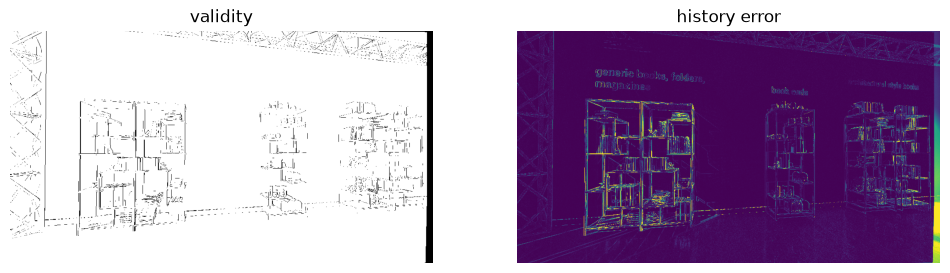

In [19]:
plt.figure(figsize=(12, 4))
plt.subplot(121)
plt.imshow(valid.numpy(), cmap="gray")
plt.title("validity")
plt.axis("off")
plt.subplot(122)
plt.imshow(err.numpy(), vmax=np.percentile(err.numpy(), 99))
plt.title("history error")
plt.axis("off")


In [ ]:
# Training 

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    print("device:", torch.cuda.get_device_name(0))

model = UnetStem(in_channels=16, out_channels=3, features=(48, 96, 192, 384), stem=True).to(device)
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
epochs = 60

CONFIG = {
    "in_channels": 16,
    "features": (48, 96, 192, 384),
    "patch": 256,
    "ppf": 16,
    "lr": 1e-4,
    "eps": EPS,
    "held_out": sorted(HELD_OUT),
    "train_scenes": sorted({s for s, _, _ in train_clips}),
}

def save_ckpt(path, epoch, best_val, best_psnr, history):
    torch.save({
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "best_val": best_val,
        "best_psnr": best_psnr,
        "config": CONFIG,
        "history": history,
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "numpy_rng": np.random.get_state(),
    }, path + ".tmp")
    os.replace(path + ".tmp", path)

device: AMD Radeon RX 7900 XTX


In [ ]:
for s, _, c in clips:
    ds = UEClipDataset(c, transform=None, wp_stats=wp_stats[s])
    b = ds[0]
    wp = b["world_position"]
    bg = -ds.wp_center / ds.wp_scale
    print(
        f"{s:28s} scale {ds.wp_scale:9.2f}  wp [{wp.min():9.2f}, {wp.max():9.2f}]  "
        f"bg -> {bg.round(1)}"
    )

In [ ]:
RESUME = None     # set to "baseline_last.pt" to continue training
# epochs = 60 # to resume from baseline_last

history = []
start_epoch, best_val, best_psnr = 0, float("inf"), 0.0

if RESUME and os.path.exists(RESUME):
    ck = torch.load(RESUME, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])
    start_epoch = ck["epoch"] + 1
    best_val, best_psnr = ck["best_val"], ck["best_psnr"]
    history = ck.get("history", [])
    torch.set_rng_state(ck["torch_rng"].cpu())
    np.random.set_state(ck["numpy_rng"])
    if ck["cuda_rng"] is not None:
        torch.cuda.set_rng_state_all([s.cpu() for s in ck["cuda_rng"]])
    print(f"resumed from epoch {ck['epoch']} (best full-frame {best_psnr:.2f} dB)")

for epoch in range(start_epoch, epochs):
    model.train()
    train_loss, n_train = 0.0, 0

    for batch in train_loader:
        x = make_input(batch).to(device, non_blocking=True)
        y = batch["reference"].to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.bfloat16,
                            enabled=(device.type == "cuda")):
            pred = model(x)
            loss = criterion(pred, y) + 0.5 * gradient_loss(pred, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        n_train += 1

    model.eval()
    val_loss, val_psnr, n_val, n_img = 0.0, 0.0, 0, 0

    with torch.no_grad():
        for batch in val_loader:
            x = make_input(batch).to(device, non_blocking=True)
            y = batch["reference"].to(device, non_blocking=True)
            a = batch["albedo"].to(device, non_blocking=True)

            with torch.autocast("cuda", dtype=torch.bfloat16,
                                enabled=(device.type == "cuda")):
                pred = model(x)
                loss = criterion(pred, y) + 0.5 * gradient_loss(pred, y)

            val_loss += loss.item()
            val_psnr += psnr(pred, y, a)
            n_val += 1
            n_img += x.shape[0]

    train_epoch = train_loss / n_train
    val_epoch = val_loss / n_val
    val_psnr_db = val_psnr / n_img

    # scheduler.step(val_epoch)

    print(f"epoch:{epoch + 1:3d}  train:{train_epoch:.4f}  val:{val_epoch:.4f}  "
          f"crop-psnr:{val_psnr_db:.2f} dB  lr:{optimizer.param_groups[0]['lr']:.2e}")

    full_db = evaluate_scenes(model, val_clips, device, tag=f"(epoch {epoch + 1})")

    history.append({
        "epoch": epoch,
        "train": train_epoch,
        "val": val_epoch,
        "crop_psnr": val_psnr_db,
        "full_psnr": full_db,
        "lr": optimizer.param_groups[0]["lr"],
    })

    if full_db > best_psnr:
        best_val, best_psnr = val_epoch, full_db
        save_ckpt("baseline_best.pt", epoch, best_val, best_psnr, history)

    save_ckpt("baseline_last.pt", epoch, best_val, best_psnr, history)

print(f"\nbest full-frame PSNR {best_psnr:.2f} dB")

resumed from epoch 49 (best full-frame 33.12 dB)
epoch: 51  train:0.1105  val:0.0269  crop-psnr:34.51 dB  lr:1.00e-04
  ClassicSponzaUnreal   33.24 dB
  mean                  33.24 dB (epoch 51)
epoch: 52  train:0.1096  val:0.0269  crop-psnr:34.52 dB  lr:1.00e-04
  ClassicSponzaUnreal   33.25 dB
  mean                  33.25 dB (epoch 52)
epoch: 53  train:0.1094  val:0.0271  crop-psnr:34.39 dB  lr:1.00e-04
  ClassicSponzaUnreal   33.19 dB
  mean                  33.19 dB (epoch 53)
epoch: 54  train:0.1098  val:0.0275  crop-psnr:34.30 dB  lr:1.00e-04
  ClassicSponzaUnreal   33.09 dB
  mean                  33.09 dB (epoch 54)
epoch: 55  train:0.1094  val:0.0269  crop-psnr:34.54 dB  lr:1.00e-04
  ClassicSponzaUnreal   33.30 dB
  mean                  33.30 dB (epoch 55)
epoch: 56  train:0.1097  val:0.0268  crop-psnr:34.46 dB  lr:1.00e-04
  ClassicSponzaUnreal   33.25 dB
  mean                  33.25 dB (epoch 56)
epoch: 57  train:0.1092  val:0.0269  crop-psnr:34.55 dB  lr:1.00e-04
  Clas

In [ ]:
# Eval 
ck = torch.load("baseline_best.pt", map_location=device, weights_only=False)
model.load_state_dict(ck["model"])
print(f"loaded epoch {ck['epoch'] + 1}, full-frame {ck['best_psnr']:.2f} dB\n")

print("held out:")
out_val = evaluate_scenes(model, val_clips, device)
in_val = input_psnr(val_clips, device)

print("\ntrain scenes (first two):")
evaluate_scenes(model, train_clips[:2], device, tag="(train)")
input_psnr(train_clips[:2], device)

loaded epoch 60, full-frame 33.45 dB

held out:
  ClassicSponzaUnreal   33.45 dB
  mean                  33.45 dB 
  ClassicSponzaUnreal  input  15.25 dB

train scenes (first two):
  BookStackBPV2   33.42 dB
  mean            33.42 dB (train)
  BookStackBPV2  input  14.56 dB


{'BookStackBPV2': 14.559953865252043}

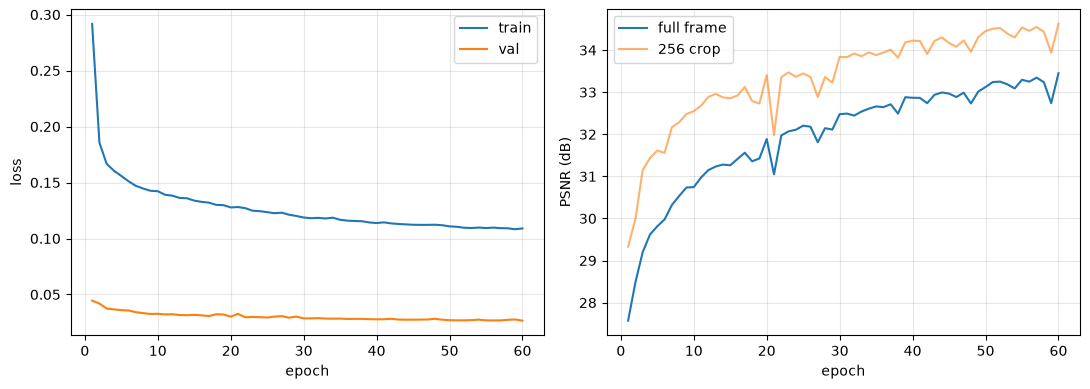

In [31]:
h = history or ck["history"]
ep = [r["epoch"] + 1 for r in h]

plt.figure(figsize=(11, 4))
plt.subplot(121)
plt.plot(ep, [r["train"] for r in h], label="train")
plt.plot(ep, [r["val"] for r in h], label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=.3)

plt.subplot(122)
plt.plot(ep, [r["full_psnr"] for r in h], label="full frame")
plt.plot(ep, [r["crop_psnr"] for r in h], label="256 crop", alpha=.6)
plt.xlabel("epoch"); plt.ylabel("PSNR (dB)"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout()

In [133]:
b = next(iter(val_loader))
x = make_input(b).to(device)
y = b["reference"].to(device)
with torch.no_grad():
    pred = model(x)
print(f"pred  mean {pred.mean():.3f}  std {pred.std():.3f}")
print(f"ref   mean {y.mean():.3f}  std {y.std():.3f}")

pred  mean 0.085  std 0.110
ref   mean 0.100  std 0.127


In [ ]:
# FFMPEG visual sequence 
@torch.no_grad()
def dump_sequence(model, scene, clip, wp_stats, out_dir, device):
    """Writes input / output / reference PNGs for every frame of one clip.

    Flicker is what temporal accumulation fixes and PSNR cannot see, so encode
    these at 4-10 fps and watch the output against the reference.
    """
    os.makedirs(out_dir, exist_ok=True)
    model.eval()

    ds = UEClipDataset(
        clip,
        transform=None,
        patch=None,
        patches_per_frame=1,
        train=False,
        wp_stats=wp_stats[scene],
    )

    for i in range(len(ds)):
        b = ds[i]
        x = make_input({k: v[None] for k, v in b.items()}).to(device)
        a = b["albedo"][None].to(device)

        with torch.autocast(
            "cuda", dtype=torch.bfloat16, enabled=(device.type == "cuda")
        ):
            pred = model(x)

        denom = a.clamp(min=0) + EPS
        out = tonemap(torch.expm1(pred.float()).clamp(min=0) * denom)
        inp = tonemap(
            torch.expm1(b["color"][None].to(device).float()).clamp(min=0) * denom
        )
        ref = tonemap(
            torch.expm1(b["reference"][None].to(device).float()).clamp(min=0) * denom
        )

        for name, t in [("input", inp), ("output", out), ("reference", ref)]:
            img = (
                (t[0].permute(1, 2, 0).cpu().numpy() * 255)
                .clip(0, 255)
                .astype(np.uint8)
            )
            cv2.imwrite(f"{out_dir}/{name}_{i:03d}.png", img[:, :, ::-1])

    print(f"wrote {len(ds)} frames x 3 to {out_dir}")


scene, _, clip = val_clips[0]
dump_sequence(model, scene, clip, wp_stats, f"compare/{scene}", device)

wrote 19 frames x 3 to compare/ClassicSponzaUnreal


```bash
cd compare/<scene>
ffmpeg -framerate 4 -start_number 0 -i input_%03d.png \
       -framerate 4 -start_number 0 -i output_%03d.png \
       -framerate 4 -start_number 0 -i reference_%03d.png \
       -filter_complex hstack=inputs=3 -c:v libx264 -crf 18 -pix_fmt yuv420p compare.mp4
```

In [ ]:
# ! cd compare/ClassicSponzaUnreal/
# ! ffmpeg -framerate 4 -start_number 0 -i input_%03d.png \
#        -framerate 4 -start_number 0 -i output_%03d.png \
#        -framerate 4 -start_number 0 -i reference_%03d.png \
#        -filter_complex hstack=inputs=3 -c:v libx264 -crf 18 -pix_fmt yuv420p compare.mp4


ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [ ]:
def tonemap_np(x):
    x = np.clip(x, 0, None)
    x = x / (1.0 + x)
    return np.clip(x, 0, 1) ** (1 / 2.2)


def inter_seed(path_a, path_b, plot=True):
    a, b = load_exr(path_a), load_exr(path_b)
    mse = ((tonemap_np(a) - tonemap_np(b)) ** 2).mean()
    pair_db = 10 * np.log10(1.0 / mse)

    print(f"pairwise PSNR   {pair_db:6.2f} dB")
    print(f"est. per-render {pair_db + 3.01:6.2f} dB")
    print(f"mean abs diff   {np.abs(a - b).mean():.5f}")

    if plot:
        d = np.abs(a - b).mean(axis=2)
        plt.imshow(d, vmax=np.percentile(d, 99.5))
        plt.colorbar()
        plt.title("inter-seed difference")
        plt.axis("off")
    return a, b

# Two consecutive frames of a static-camera moment: same geometry, different seed.
# a, b = inter_seed("0000_B.exr", "0001_B.exr")

In [ ]:
'''
Thoeritical Inference Latency on 7900xtx
Spanning various channels and levels at 960 x 528  
'''

from UNet import UnetStem

import time
import torch


@torch.no_grad()
def bench(
    model,
    shape=(1, 16, 528, 960),
    dtype=torch.bfloat16,
    device="cuda",
    warmup=50,
    iters=200,
):
    '''Median forward-pass latency. Random weights are fine — latency doesn't
    depend on their values, only on shapes.'''
    model = model.to(device).eval()
    x = torch.randn(*shape, device=device)

    def once():
        with torch.autocast(device, dtype=dtype, enabled=dtype is not None):
            return model(x)

    for _ in range(warmup):  # MIOpen/cuDNN autotuning settles here
        once()
    torch.cuda.synchronize()

    torch.cuda.reset_peak_memory_stats()
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)

    times = []
    for _ in range(iters):
        start.record()
        once()
        end.record()
        torch.cuda.synchronize()
        times.append(start.elapsed_time(end))

    t = torch.tensor(times)
    return {
        "median_ms": t.median().item(),
        "p95_ms": t.quantile(0.95).item(),
        "min_ms": t.min().item(),
        "peak_mb": torch.cuda.max_memory_allocated() / 1e6,
        "params_m": sum(p.numel() for p in model.parameters()) / 1e6,
    }

CANDIDATES = [
    ("(64,128,256) previous", dict(features=(64, 128, 256))),
    ("(48,96,192)", dict(features=(48, 96, 192))),
    ("(32,64,128)", dict(features=(32, 64, 128))),
    ("(48, 96, 192, 384) current", dict(features=(48, 96, 192, 384))),
]

print(f"{'config':26s}{'params':>9s}{'median':>10s}{'p95':>9s}{'VRAM':>9s}")
print("-" * 63)
for name, kw in CANDIDATES:
    m = UnetStem(in_channels=16, out_channels=3, **kw)
    r = bench(m)
    print(
        f"{name:26s}{r['params_m']:8.2f}M{r['median_ms']:9.2f}ms"
        f"{r['p95_ms']:8.2f}ms{r['peak_mb']:8.0f}MB"
    )
    del m
    torch.cuda.empty_cache()

config                       params    median      p95     VRAM
---------------------------------------------------------------
(64,128,256) previous         7.96M    20.40ms   20.60ms     952MB
(48,96,192)                   4.48M    14.45ms   14.58ms     732MB
(32,64,128)                   1.99M     8.03ms    8.10ms     517MB
(48, 96, 192, 384)           18.05M    16.82ms   16.95ms     822MB


In [ ]:
# upConv reduced from 3x3 to 1x1 with stem application

@torch.no_grad()
def bench(
    model,
    shape=(1, 16, 528, 960),
    dtype=torch.bfloat16,
    device="cuda",
    warmup=50,
    iters=200,
):
    model = model.to(device).eval()
    x = torch.randn(*shape, device=device)

    def once():
        with torch.autocast(device, dtype=dtype, enabled=dtype is not None):
            return model(x)

    for _ in range(warmup):  
        once()
    torch.cuda.synchronize()

    torch.cuda.reset_peak_memory_stats()
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)

    times = []
    for _ in range(iters):
        start.record()
        once()
        end.record()
        torch.cuda.synchronize()
        times.append(start.elapsed_time(end))

    t = torch.tensor(times)
    return {
        "median_ms": t.median().item(),
        "p95_ms": t.quantile(0.95).item(),
        "min_ms": t.min().item(),
        "peak_mb": torch.cuda.max_memory_allocated() / 1e6,
        "params_m": sum(p.numel() for p in model.parameters()) / 1e6,
    }


CANDIDATES = [
    ("(64,128,256) previous", dict(features=(64, 128, 256))),
    ("(48,96,192)", dict(features=(48, 96, 192))),
    ("(32,64,128)", dict(features=(32, 64, 128))),
    ("(48, 96, 192, 384)", dict(features=(48, 96, 192, 384))),
]

print(f"{'config':26s}{'params':>9s}{'median':>10s}{'p95':>9s}{'VRAM':>9s}")
print("-" * 63)
for name, kw in CANDIDATES:
    m = UnetStem(in_channels=16, out_channels=3, stem=True, **kw)
    r = bench(m)
    print(
        f"{name:26s}{r['params_m']:8.2f}M{r['median_ms']:9.2f}ms"
        f"{r['p95_ms']:8.2f}ms{r['peak_mb']:8.0f}MB"
    )
    del m
    torch.cuda.empty_cache()

config                       params    median      p95     VRAM
---------------------------------------------------------------
(64,128,256) previous         8.00M     5.15ms    5.26ms     356MB
(48,96,192)                   4.50M     3.83ms    3.89ms     285MB
(32,64,128)                   2.00M     2.46ms    2.53ms     221MB
(48, 96, 192, 384)           18.07M     4.71ms    4.76ms     371MB


In [ ]:
# ONNX Export
from new_unet import UnetStem

def load_model(path, device="cuda"):
    ck = torch.load(path, map_location=device, weights_only=False)
    cfg = ck["config"]
    model = UnetStem(
        in_channels=cfg["in_channels"], out_channels=3, stem=True, features=tuple(cfg["features"])
    ).to(device)
    model.load_state_dict(ck["model"])
    model.eval()
    print(
        f"epoch {ck['epoch'] + 1}  full-frame {ck['best_psnr']:.2f} dB  "
        f"in_channels {cfg['in_channels']}  features {cfg['features']}"
    )
    return model, ck


model, ck = load_model("./baseline_best.pt", device="cpu")
model.eval()

dummy = torch.randn(1, 16, 192, 528, 960)

RESOLUTIONS = [(960, 528), (1280, 720), (1920, 1080), (2560, 1440)]

for w, h in RESOLUTIONS:
    assert h % 8 == 0 and w % 8 == 0, f"{w}x{h} not divisible by 8"
    torch.onnx.export(
        model,
        torch.randn(1, 16, h, w),
        f"denoiser_{w}x{h}.onnx",
        input_names=["input"],
        output_names=["output"],
        opset_version=17,
        do_constant_folding=True,
        dynamo=False,
    )
    print(f"denoiser_{w}x{h}.onnx")

epoch 60  full-frame 33.45 dB  in_channels 16  features (48, 96, 192, 384)


/tmp/ipykernel_246601/711453832.py:28: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


denoiser_960x528.onnx
denoiser_1280x720.onnx
denoiser_1600x896.onnx
denoiser_1920x1080.onnx
denoiser_2560x1440.onnx


In [ ]:
import onnx

m = onnx.load("denoiser_2560x1440.onnx")
ops = {}
for n in m.graph.node:
    ops[n.op_type] = ops.get(n.op_type, 0) + 1
print(len(m.graph.node), "nodes")
print(dict(sorted(ops.items(), key=lambda x: -x[1])))

91 nodes
{'Conv': 28, 'Constant': 20, 'Relu': 18, 'Resize': 8, 'Concat': 8, 'Shape': 4, 'Slice': 4, 'DepthToSpace': 1}


In [ ]:
# Parity check

import onnxruntime as ort, numpy as np

sess = ort.InferenceSession("denoiser.onnx", providers=["CPUExecutionProvider"])
x = torch.randn(1, 16, 528, 960)
with torch.no_grad():
    ref = model(x).numpy()
got = sess.run(None, {"input": x.numpy()})[0]
print("max abs diff:", np.abs(ref - got).max())

max abs diff: 7.1525574e-07


In [30]:
'''
Export to .mxr using MIGraphX
'''
# build_mxr.py
import torch, migraphx

CKPT = "./baseline_best.pt"
#RESOLUTIONS = [(960, 528), (1280, 720), (1920, 1080), (2560, 1440)]
RESOLUTIONS = [(960, 528),(1920, 1080), (2560, 1440)]

IN_CH, OUT_CH = 16, 3
ARCH = "gfx1100"
EXHAUSTIVE = False  # flip to True once the pipeline is proven

model = UnetStem(IN_CH, OUT_CH, features=(48, 96, 192, 384), stem=True)
sd = torch.load(CKPT, map_location="cpu", weights_only=False)
model.load_state_dict(sd.get("model", sd))
model.eval()

gpu = migraphx.get_target("gpu")

for W, H in RESOLUTIONS:
    onnx_path = f"denoiser_{W}x{H}.onnx"
    mxr_path = f"denoiser_{W}x{H}_{ARCH}.mxr"

    torch.onnx.export(
        model,
        (torch.zeros(1, IN_CH, H, W),),
        onnx_path,
        input_names=["input"],
        output_names=["output"],
        opset_version=17,
        dynamo=True,
    )
    print(f"exported {onnx_path}")

    prog = migraphx.parse_onnx(onnx_path)
    migraphx.quantize_fp16(prog)
    prog.compile(gpu, offload_copy=True, fast_math=True, exhaustive_tune=EXHAUSTIVE)
    migraphx.save(prog, mxr_path)
    print(f"compiled {mxr_path}")

W1012 12:49:27.372000 8250 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `UnetStem([...]` with `torch.export.export(..., strict=False)`...


/home/prxnce-lixh/Documents/M_L/unet-denoiser/unet-env/lib/python3.13/site-packages/torch/backends/cudnn/__init__.py:177: UserWarning: cuDNN Benchmark limit is not supported in MIOpen and will have no effect. (Triggered internally at /__w/rockrel/rockrel/external-builds/pytorch/pytorch/torch/csrc/cuda/Module.cpp:2107.)
  torch._C._cuda_set_cudnn_benchmark_limit(_benchmark_limit)


[torch.onnx] Obtain model graph for `UnetStem([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).


...

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
exported denoiser_1920x1080.onnx


W1012 12:50:25.247000 8250 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


compiled denoiser_1920x1080_gfx1100.mxr
[torch.onnx] Obtain model graph for `UnetStem([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `UnetStem([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
exported denoiser_2560x1440.onnx
compiled denoiser_2560x1440_gfx1100.mxr
